In [ ]:

# IMPORT REQUIRED LIBRARIES

import os
from pathlib import Path

# Define dataset directory
DATASET_DIR = Path("Dataset")

# Check whether the dataset exists
if DATASET_DIR.exists():
    print("Dataset folder found!")
else:
    print("Dataset folder not found.")
    print("Please check the folder location.")

# INSPECT FOLDER STRUCTURE

if DATASET_DIR.exists():

    for root, dirs, files in os.walk(DATASET_DIR):

        level = root.replace(str(DATASET_DIR), "").count(os.sep)

        indent = " " * 4 * level

        print(f"{indent}{os.path.basename(root)}/")

        for file in files[:5]:
            print(f"{indent}    {file}")

# COUNT IMAGE FILES

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

if DATASET_DIR.exists():

    image_files = [
        file for file in DATASET_DIR.rglob("*")
        if file.is_file()
        and file.suffix.lower() in image_extensions
    ]

    print("\nTotal number of images:", len(image_files))

    print("\nImage formats:")

    for extension in image_extensions:
        count = sum(
            1 for file in image_files
            if file.suffix.lower() == extension
        )

        if count > 0:
            print(extension, ":", count)


Dataset folder found!
Dataset/
    test/
        class0/
            not_nicolas_147.jpg
            not_nicolas_148.jpg
            not_nicolas_149.jpg
            not_nicolas_150.jpg
            not_nicolas_151.jpg
        class1/
            Nic_Cage_145.jpg
            Nic_Cage_146.jpg
            Nic_Cage_147.jpg
            Nic_Cage_148.jpg
            Nic_Cage_149.jpg
    train/
        class0/
            not_nicolas_0.jpg
            not_nicolas_1.jpg
            not_nicolas_10.jpg
            not_nicolas_100.jpg
            not_nicolas_101.jpg
        class1/
            Nic_Cage_0.jpg
            Nic_Cage_1.jpg
            Nic_Cage_10.jpg
            Nic_Cage_100.jpg
            Nic_Cage_101.jpg

Total number of images: 414

Image formats:
.jpg : 414


In [ ]:
# DATASET CLASS DISTRIBUTION

from pathlib import Path

train_dir = DATASET_DIR / "train"
test_dir = DATASET_DIR / "test"

classes = {
    "class0": "Not Nicolas Cage",
    "class1": "Nicolas Cage"
}

for dataset_name, dataset_path in [
    ("Training", train_dir),
    ("Testing", test_dir)
]:

    print(f"\n{dataset_name} Dataset")
    print("-" * 35)

    for folder, label in classes.items():

        folder_path = dataset_path / folder

        count = len([
            file for file in folder_path.iterdir()
            if file.suffix.lower() in image_extensions
        ])

        print(f"{label}: {count} images")




Training Dataset
-----------------------------------
Not Nicolas Cage: 147 images
Nicolas Cage: 143 images

Testing Dataset
-----------------------------------
Not Nicolas Cage: 63 images
Nicolas Cage: 61 images


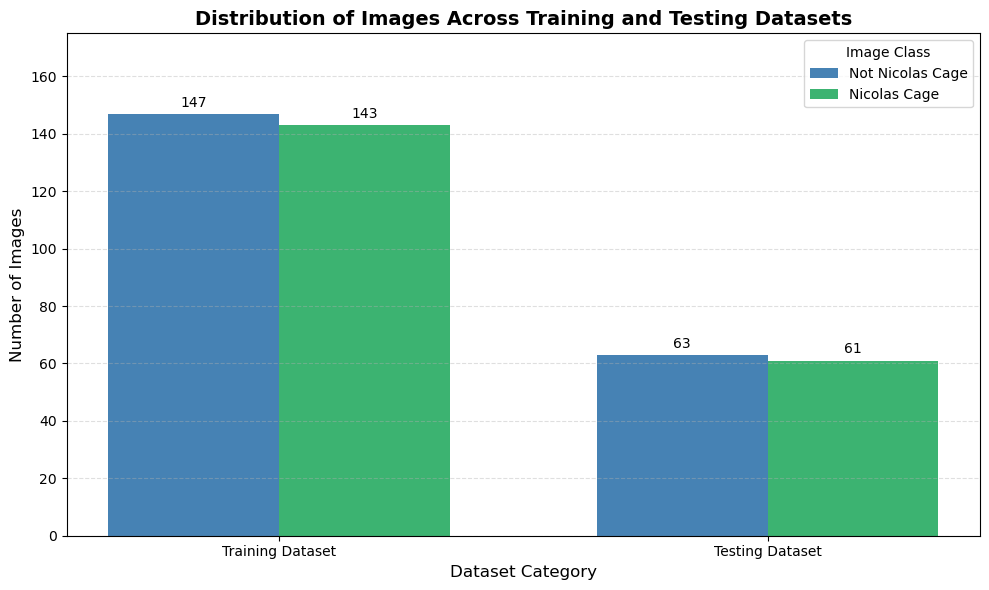

In [ ]:
# VISUALISE DATASET DISTRIBUTION

import matplotlib.pyplot as plt
import numpy as np

# Dataset image counts
datasets = ["Training Dataset", "Testing Dataset"]

not_cage = [147, 63]
nicolas_cage = [143, 61]

# Define bar positions
x = np.arange(len(datasets))
width = 0.35

# Create figure
plt.figure(figsize=(10, 6))

# Plot bars
bars1 = plt.bar(
    x - width/2,
    not_cage,
    width,
    label="Not Nicolas Cage",
    color="steelblue"
)

bars2 = plt.bar(
    x + width/2,
    nicolas_cage,
    width,
    label="Nicolas Cage",
    color="mediumseagreen"
)

# Add count labels above bars
plt.bar_label(bars1, padding=3, fontsize=10)
plt.bar_label(bars2, padding=3, fontsize=10)

# Chart formatting
plt.title(
    "Distribution of Images Across Training and Testing Datasets",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Dataset Category", fontsize=12)
plt.ylabel("Number of Images", fontsize=12)

plt.xticks(x, datasets)
plt.legend(title="Image Class")

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.ylim(0, 175)

plt.tight_layout()
plt.show()


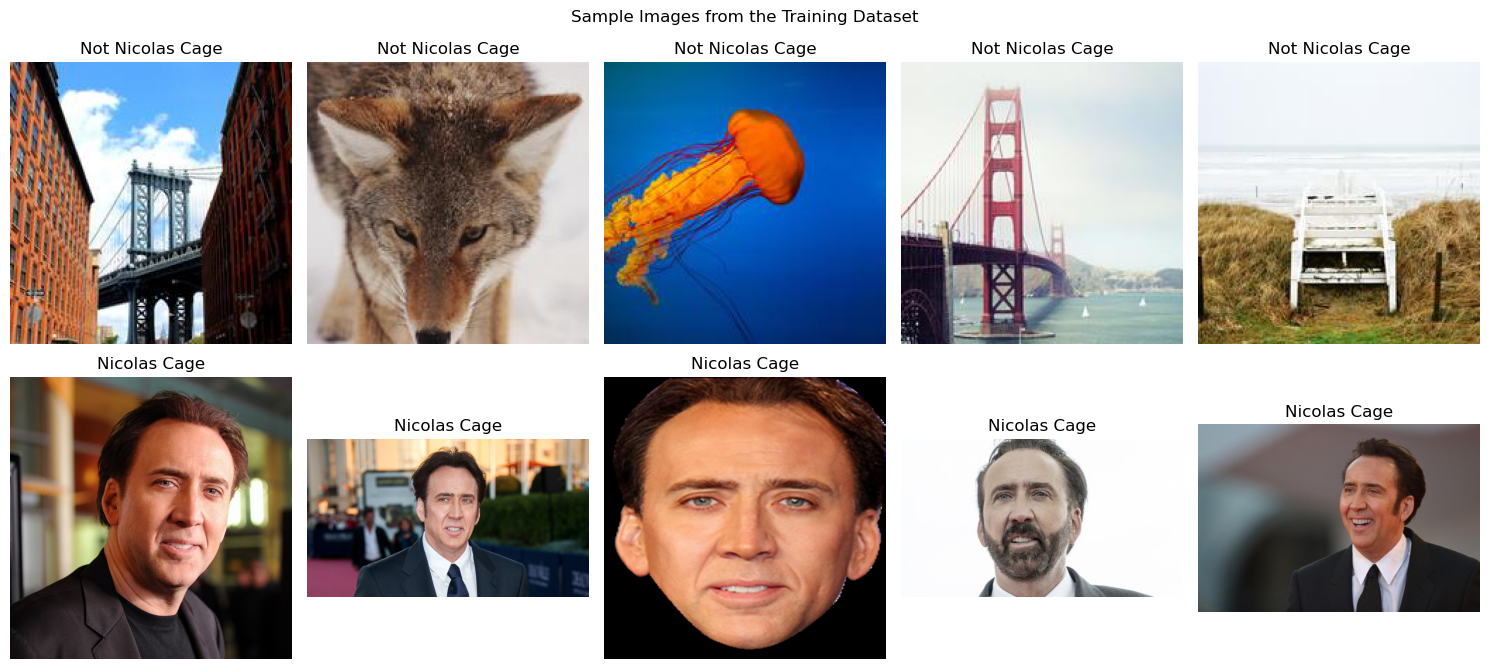

In [ ]:
# DISPLAY SAMPLE IMAGES

import matplotlib.pyplot as plt
from PIL import Image
import random

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for row, (folder, label) in enumerate(classes.items()):

    folder_path = train_dir / folder

    images = [
        file for file in folder_path.iterdir()
        if file.suffix.lower() in image_extensions
    ]

    sample_images = random.sample(
        images,
        min(5, len(images))
    )

    for col, image_path in enumerate(sample_images):

        img = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].set_title(label)
        axes[row, col].axis("off")

plt.suptitle("Sample Images from the Training Dataset")
plt.tight_layout()
plt.show()


In [ ]:
# CHECK IMAGE DIMENSIONS

from collections import Counter

image_dimensions = []

for image_path in (train_dir).rglob("*"):

    if image_path.suffix.lower() in image_extensions:

        try:
            with Image.open(image_path) as img:
                image_dimensions.append(img.size)

        except Exception as e:
            print("Problem with image:", image_path, e)

dimension_counts = Counter(image_dimensions)

print("Number of different image dimensions:",
      len(dimension_counts))

print("\nMost common image dimensions:")

for dimension, count in dimension_counts.most_common(10):
    print(f"{dimension}: {count} images")


Number of different image dimensions: 122

Most common image dimensions:
(200, 200): 147 images
(800, 450): 4 images
(920, 584): 3 images
(425, 425): 3 images
(600, 600): 3 images
(780, 438): 3 images
(630, 1200): 2 images
(1024, 683): 2 images
(618, 410): 2 images
(624, 385): 2 images


In [ ]:
#IMPORT TENSORFLOW

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [ ]:
#LOAD AND PREPROCESS DATA

IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

# Load training images and create validation split

train_dataset = keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    validation_split=0.20,
    subset="training",
    seed=SEED,
    shuffle=True
)

# Load validation images

validation_dataset = keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    shuffle=True
)

# Load testing images separately

test_dataset = keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    color_mode="rgb",
    shuffle=False
)

print("\nClass names:", train_dataset.class_names)


Found 290 files belonging to 2 classes.


Using 232 files for training.
Found 290 files belonging to 2 classes.
Using 58 files for validation.
Found 124 files belonging to 2 classes.

Class names: ['class0', 'class1']


In [ ]:
# CHECK DATASET SIZES

train_count = sum(
    images.shape[0]
    for images, labels in train_dataset
)

validation_count = sum(
    images.shape[0]
    for images, labels in validation_dataset
)

test_count = sum(
    images.shape[0]
    for images, labels in test_dataset
)

print("Training images:", train_count)
print("Validation images:", validation_count)
print("Testing images:", test_count)

print("\nTotal images:",
      train_count + validation_count + test_count)


Training images: 232
Validation images: 58
Testing images: 124

Total images: 414


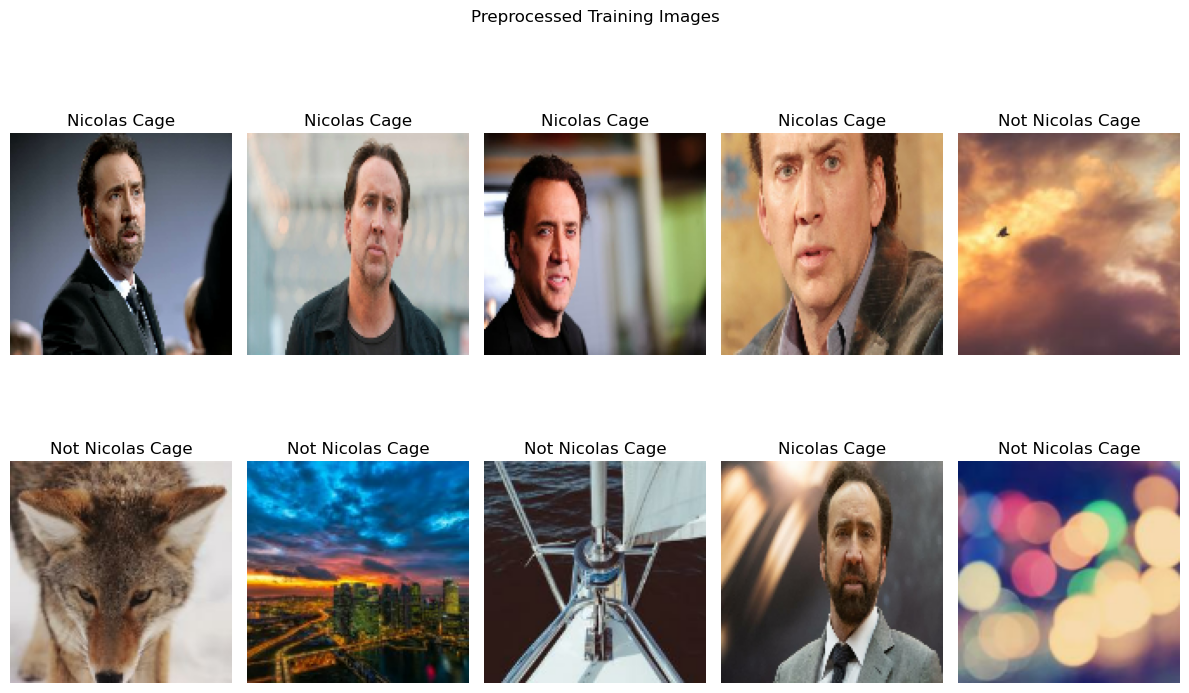

In [ ]:
# DISPLAY PREPROCESSED IMAGES

plt.figure(figsize=(12, 8))

for images, labels in train_dataset.take(1):

    for i in range(min(10, len(images))):

        plt.subplot(2, 5, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label = int(labels[i].numpy()[0])

        class_name = (
            "Nicolas Cage"
            if label == 1
            else "Not Nicolas Cage"
        )

        plt.title(class_name)
        plt.axis("off")

plt.suptitle("Preprocessed Training Images")
plt.tight_layout()
plt.show()


In [ ]:
# BUILD THE CNN ARCHITECTURE

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Rescaling,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    RandomFlip,
    RandomRotation,
    RandomZoom
)

# Define CNN architecture

model = Sequential([

    # Input layer
    Input(shape=(128, 128, 3)),

    # Data augmentation
    RandomFlip("horizontal"),
    RandomRotation(0.08),
    RandomZoom(0.1),

    # Normalise pixel values (0-255 to 0-1)
    Rescaling(1./255),

    # First convolutional block
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Second convolutional block
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Third convolutional block
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Convert feature maps into a vector
    Flatten(),

    # Fully connected layer
    Dense(128, activation="relu"),

    # Reduce overfitting
    Dropout(0.5),

    # Binary classification output
    Dense(1, activation="sigmoid")

])

print("CNN architecture created successfully!")


CNN architecture created successfully!


In [ ]:
# DISPLAY MODEL SUMMARY

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# COMPILE THE CNN

model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]

)

print("CNN compiled successfully!")


CNN compiled successfully!


In [ ]:
# OPTIMISE DATASET PERFORMANCE

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(
    buffer_size=AUTOTUNE
)

validation_dataset = validation_dataset.prefetch(
    buffer_size=AUTOTUNE
)

test_dataset = test_dataset.prefetch(
    buffer_size=AUTOTUNE
)

print("Datasets prepared for training!")


Datasets prepared for training!


In [ ]:
# CONFIGURE CALLBACKS

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

callbacks = [
    early_stopping,
    reduce_lr
]

print("Training callbacks configured!")


Training callbacks configured!


In [ ]:
#TRAIN THE CNN MODEL

EPOCHS = 20

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

print("\nCNN training completed!")


Epoch 1/20


c:\Users\ksomp\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 123ms/step - accuracy: 0.5259 - loss: 0.6983 - precision: 0.5195 - recall: 0.6897 - val_accuracy: 0.5000 - val_loss: 0.6623 - val_precision: 0.4821 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 102ms/step - accuracy: 0.7026 - loss: 0.5767 - precision: 0.6424 - recall: 0.9138 - val_accuracy: 0.7414 - val_loss: 0.5610 - val_precision: 0.6429 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - accuracy: 0.8362 - loss: 0.4067 - precision: 0.8047 - recall: 0.8879 - val_accuracy: 0.9483 - val_loss: 0.2437 - val_precision: 0.9286 - val_recall: 0.9630 - learning_rate: 0.0010
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 105ms/step - accuracy: 0.8836 - loss: 0.2813 - precision: 0.8618 - recall: 0.9138 - val_accuracy: 0.9655 - val_loss: 0.1937 - val_precision: 1.0000 - val_recall: 0.9259 - learning_rate: 0.0010
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - accuracy: 0.9095 - loss: 0.2156 

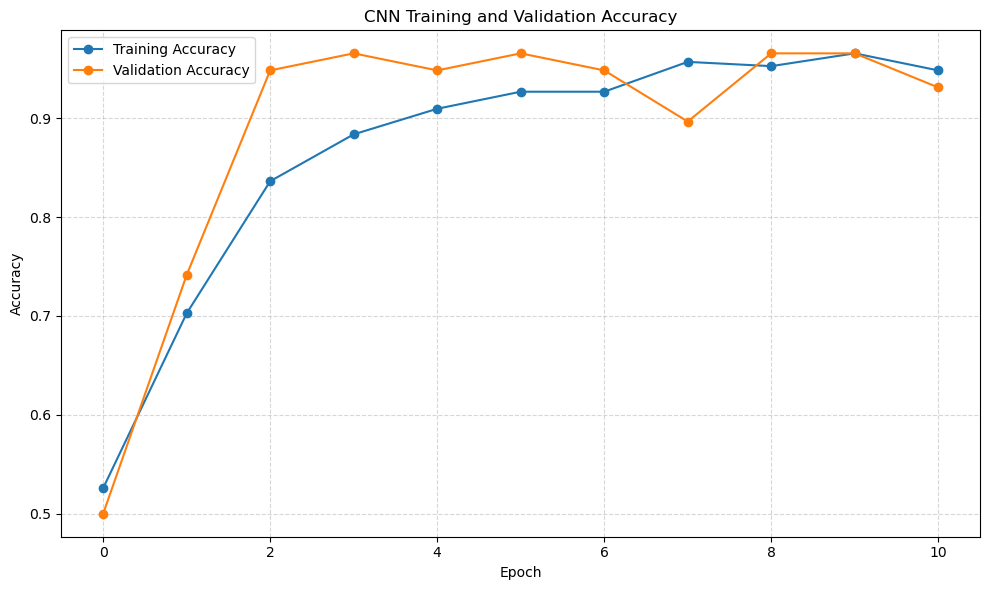

In [ ]:
#ACCURACY GRAPH

plt.figure(figsize=(10, 6))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


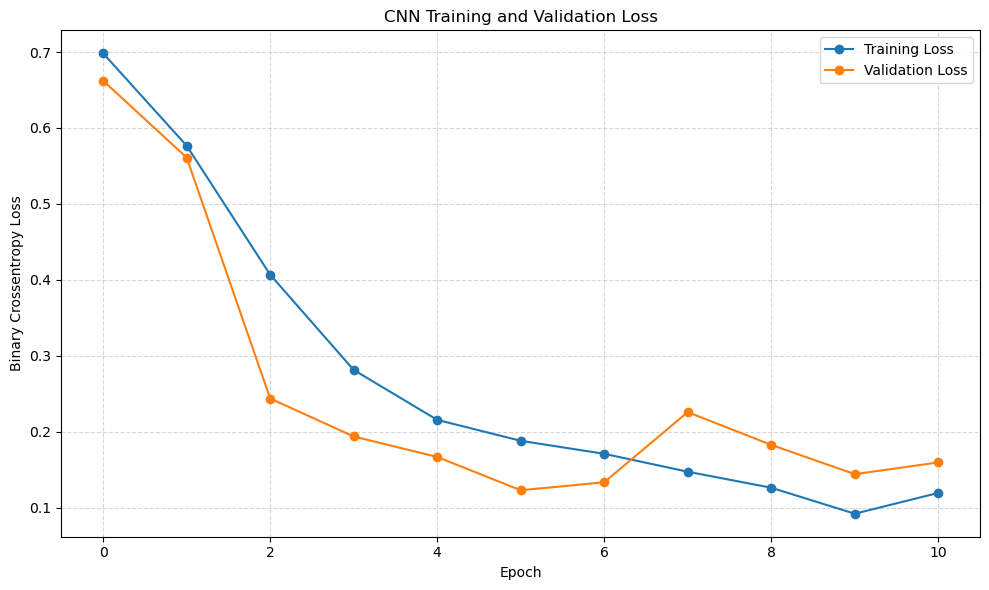

In [ ]:
# LOSS GRAPH

plt.figure(figsize=(10, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy Loss")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


In [ ]:
#EVALUATE CNN ON TEST DATA

test_results = model.evaluate(
    test_dataset,
    verbose=1,
    return_dict=True
)

print("\nCNN TEST RESULTS")
print("=" * 40)

for metric, value in test_results.items():
    print(f"{metric.capitalize():15s}: {value:.4f}")



4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8790 - loss: 0.3108 - precision: 0.8966 - recall: 0.8525      

CNN TEST RESULTS
Accuracy       : 0.8790
Loss           : 0.3108
Precision      : 0.8966
Recall         : 0.8525


In [ ]:
#GENERATE TEST PREDICTIONS

import numpy as np

# Get actual labels
y_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_dataset
]).astype(int)

# Generate predicted probabilities
y_prob = model.predict(test_dataset, verbose=1).ravel()

# Convert probabilities into class predictions
y_pred = (y_prob >= 0.5).astype(int)

print("Actual labels:", y_true.shape)
print("Predicted labels:", y_pred.shape)

print("\nFirst 10 predictions:")
print(y_pred[:10])


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
Actual labels: (124,)
Predicted labels: (124,)

First 10 predictions:
[0 0 0 0 1 0 0 0 0 0]


In [ ]:
#CLASSIFICATION REPORT

from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=[
            "Not Nicolas Cage",
            "Nicolas Cage"
        ],
        digits=4,
        zero_division=0
    )
)


                  precision    recall  f1-score   support

Not Nicolas Cage     0.8636    0.9048    0.8837        63
    Nicolas Cage     0.8966    0.8525    0.8739        61

        accuracy                         0.8790       124
       macro avg     0.8801    0.8786    0.8788       124
    weighted avg     0.8798    0.8790    0.8789       124



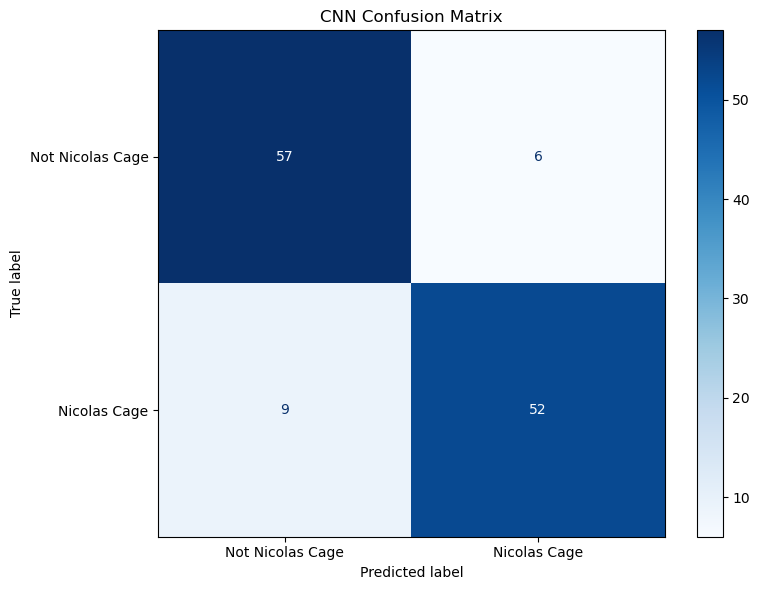

In [ ]:
#CONFUSION MATRIX

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Not Nicolas Cage",
        "Nicolas Cage"
    ]
)

fig, ax = plt.subplots(figsize=(8, 6))

display.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:
#SAVE TRAINED CNN MODEL

model.save("nicolas_cage_cnn.keras")

print("Model saved successfully!")


Model saved successfully!


In [ ]:
#FIND CORRECT PREDICTIONS

# Retrieve image paths directly from test folders
test_image_paths = []

for class_folder in ["class0", "class1"]:

    folder_path = test_dir / class_folder

    image_paths = sorted([
        str(file)
        for file in folder_path.iterdir()
        if file.suffix.lower() in image_extensions
    ])

    test_image_paths.extend(image_paths)

# Confirm paths match prediction order
print("Number of image paths:", len(test_image_paths))
print("Number of predictions:", len(y_pred))

# Find correctly classified Nicolas Cage images
cage_correct = np.where(
    (y_true == 1) & (y_pred == 1)
)[0]

# Find correctly classified non-Cage images
not_cage_correct = np.where(
    (y_true == 0) & (y_pred == 0)
)[0]

print("\nCorrect Nicolas Cage predictions:", len(cage_correct))
print("Correct Not Nicolas Cage predictions:", len(not_cage_correct))

# Select one example from each class
cage_index = cage_correct[0]
not_cage_index = not_cage_correct[0]

print("\nSelected Nicolas Cage image:")
print(test_image_paths[cage_index])

print("\nSelected Not Nicolas Cage image:")
print(test_image_paths[not_cage_index])


Number of image paths: 124
Number of predictions: 124

Correct Nicolas Cage predictions: 52
Correct Not Nicolas Cage predictions: 57

Selected Nicolas Cage image:
Dataset\test\class1\Nic_Cage_145.jpg

Selected Not Nicolas Cage image:
Dataset\test\class0\not_nicolas_147.jpg


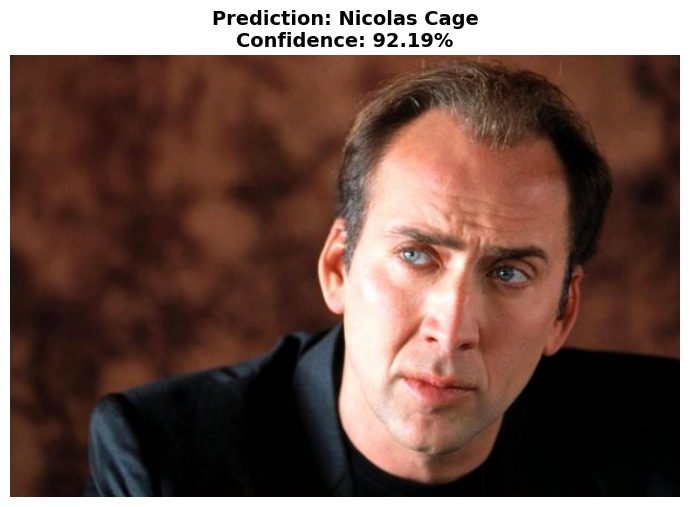

Actual class: Nicolas Cage
Predicted class: Nicolas Cage
Prediction probability: 0.9219


In [ ]:
#NICOLAS CAGE PREDICTION

# Load original image
cage_image = Image.open(
    test_image_paths[cage_index]
).convert("RGB")

# Get prediction probability
cage_probability = y_prob[cage_index]

# Display prediction
plt.figure(figsize=(7, 7))

plt.imshow(cage_image)

plt.title(
    f"Prediction: Nicolas Cage\n"
    f"Confidence: {cage_probability * 100:.2f}%",
    fontsize=14,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()
plt.show()

print("Actual class: Nicolas Cage")
print("Predicted class: Nicolas Cage")
print(f"Prediction probability: {cage_probability:.4f}")


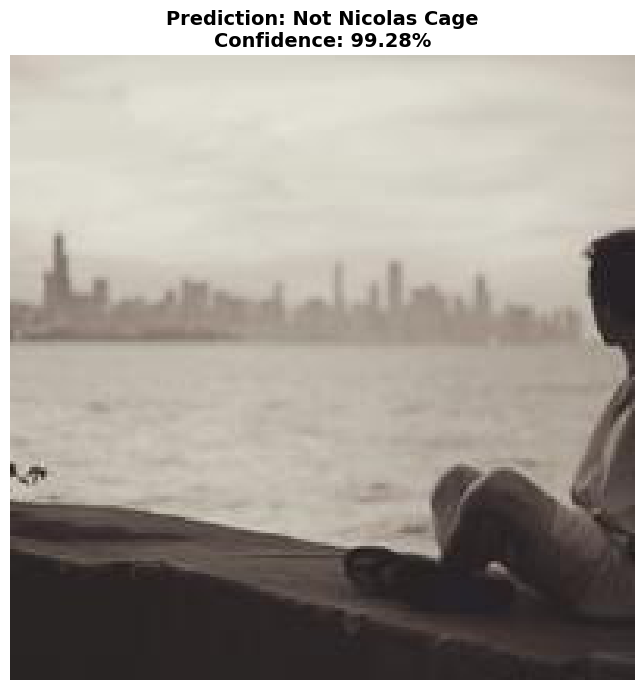

Actual class: Not Nicolas Cage
Predicted class: Not Nicolas Cage
Prediction probability: 0.9928


In [ ]:
#NOT NICOLAS CAGE PREDICTION

# Load original image
not_cage_image = Image.open(
    test_image_paths[not_cage_index]
).convert("RGB")

# Probability of Nicolas Cage
not_cage_probability = y_prob[not_cage_index]

# Calculate probability of Not Nicolas Cage
not_cage_confidence = 1 - not_cage_probability

# Display prediction
plt.figure(figsize=(7, 7))

plt.imshow(not_cage_image)

plt.title(
    f"Prediction: Not Nicolas Cage\n"
    f"Confidence: {not_cage_confidence * 100:.2f}%",
    fontsize=14,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()
plt.show()

print("Actual class: Not Nicolas Cage")
print("Predicted class: Not Nicolas Cage")
print(f"Prediction probability: {not_cage_confidence:.4f}")
